# Intraday probability and sequential evidence

Distribution selection uses chronological prediction as evidence. The serving calibration is a predeclared Poisson-based challenger. CUSUM consumes fresh five-minute increments, and empirical warning thresholds account for repeated scope and interval checks.

In [1]:
from pathlib import Path
import json
import pandas as pd
import numpy as np
import matplotlib
matplotlib.use('module://matplotlib_inline.backend_inline')
import matplotlib.pyplot as plt
from IPython.display import display

root = Path.cwd()
if not (root / 'config' / 'live_monitoring.v1.json').exists():
    root = root.parent
evidence = root / 'reports' / 'live_monitoring'
figures = evidence / 'figures'
figures.mkdir(exist_ok=True)
plt.rcParams.update({'font.size': 10, 'axes.spines.top': False, 'axes.spines.right': False,
                     'axes.grid': True, 'grid.alpha': .2, 'figure.dpi': 110})

def save(fig, name):
    fig.tight_layout()
    fig.savefig(figures / (name + '.png'), dpi=140, bbox_inches='tight')
    display(fig)
    plt.close(fig)


,minutes,scope,profile,distribution,nll,crps,coverage90
38,5,merchant-channel,merchant,Poisson,0.0713,0.0134,0.9867
36,5,merchant-channel,global,Poisson,0.0719,0.0134,0.9867
37,5,merchant-channel,channel,Poisson,0.0765,0.0135,0.9870
20,5,merchant,merchant,Poisson,0.1859,0.0432,0.9667
18,5,merchant,global,Poisson,0.1880,0.0433,0.9721
19,5,merchant,channel,Poisson,0.1913,0.0434,0.9724
11,5,channel,merchant,Poisson,0.5553,0.1883,0.9839
29,5,category,merchant,Poisson,0.5662,0.1810,0.9800
9,5,channel,global,Poisson,0.5765,0.1959,0.9777
27,5,category,global,Poisson,0.5819,0.1851,0.9799


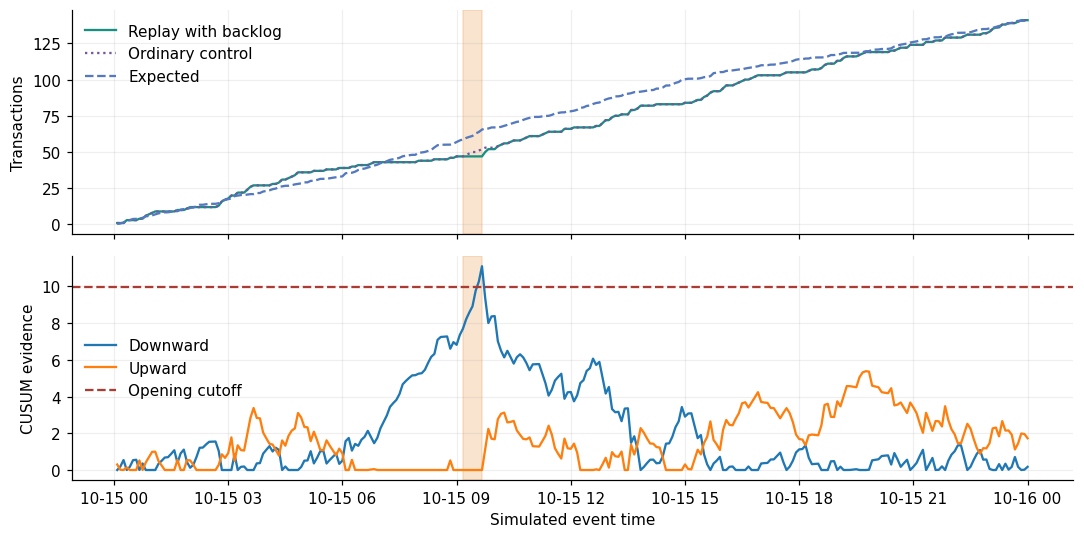

In [2]:
p = pd.read_csv(evidence / 'predictive_comparison.csv')
cols = ['minutes', 'scope', 'profile', 'distribution', 'nll', 'crps', 'coverage90']
display(p.loc[p.minutes.eq(5), cols].sort_values('nll').groupby('scope').head(3).round(4))

from src.live_monitoring.archive import Archive
from src.live_monitoring.evaluation import locked_thresholds
from src.live_monitoring.replay import Replay
a = Archive()
tape = a.tape('2026-10-15', '2026-10-15', 'backlog')
thresholds = locked_thresholds(a)
baseline = Replay(a, a.tape('2026-10-15', '2026-10-15'), thresholds, close_daily=False)
replay = Replay(a, tape, thresholds, close_daily=False)
traces = []
for i in range(tape.size):
    replay.advance()
    baseline.advance()
    traces.append(replay.signals.cusum[a.reference.index['channel','pos']].copy())
points = pd.DataFrame(replay.snapshot(('channel','pos'))['points'])
control = pd.DataFrame(baseline.snapshot(('channel','pos'))['points'])
points['time'] = pd.to_datetime(points['time'])
fig, axes = plt.subplots(2, 1, figsize=(10, 5), sharex=True)
axes[0].plot(points.time, points.cumulative, label='Replay with backlog', color='#178f82')
axes[0].plot(points.time, control.cumulative, ':', label='Ordinary control', color='#7355a1')
axes[0].plot(points.time, points.cumulative_expected, '--', label='Expected', color='#5479bf')
axes[0].set(ylabel='Transactions')
axes[0].legend(frameon=False)
axes[1].plot(points.time, np.asarray(traces)[:, 0], label='Downward')
axes[1].plot(points.time, np.asarray(traces)[:, 1], label='Upward')
axes[1].axhline(thresholds['selected'], color='#ab3c34', linestyle='--', label='Opening cutoff')
axes[1].set(xlabel='Simulated event time', ylabel='CUSUM evidence')
for ax in axes:
    ax.axvspan(tape.scenario.onset, tape.scenario.end, color='#eaa054', alpha=.28)
axes[1].legend(frameon=False)
save(fig, 'same_day_backlog_and_cusum')
